Import thư viện và thiết lập môi trường

In [2]:
from pathlib import Path
import json
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

RANDOM_SEED = 42
POSITIVE_THRESHOLD = 4.0

np.random.seed(RANDOM_SEED)

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Phase 1 environment ready!")

Pandas: 2.2.3
NumPy: 2.4.6
Phase 1 environment ready!


Xác định thư mục dự án

In [3]:
PROJECT_ROOT = Path("/content/movie-dss")

RAW_DIR = PROJECT_ROOT / "data" / "raw"
REPORT_DIR = PROJECT_ROOT / "experiments" / "eda"
FIGURE_DIR = REPORT_DIR / "figures"

for directory in [RAW_DIR, REPORT_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data:", RAW_DIR)
print("Reports:", REPORT_DIR)

Project root: /content/movie-dss
Raw data: /content/movie-dss/data/raw
Reports: /content/movie-dss/experiments/eda


Tải MovieLens Latest Small

In [4]:
DATASET_URL = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

zip_path = RAW_DIR / "ml-latest-small.zip"
dataset_dir = RAW_DIR / "ml-latest-small"

if not dataset_dir.exists():
    print("Downloading MovieLens Latest Small...")
    urllib.request.urlretrieve(DATASET_URL, zip_path)

    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(RAW_DIR)

    print("Dataset extracted successfully!")
else:
    print("Dataset already exists.")

for file_path in sorted(dataset_dir.glob("*.csv")):
    print(file_path.name)

Dataset extracted successfully!
links.csv
movies.csv
ratings.csv
tags.csv


Đọc dữ liệu

In [5]:
ratings = pd.read_csv(dataset_dir / "ratings.csv")
movies = pd.read_csv(dataset_dir / "movies.csv")
tags = pd.read_csv(dataset_dir / "tags.csv")
links = pd.read_csv(dataset_dir / "links.csv")

datasets = {
    "ratings": ratings,
    "movies": movies,
    "tags": tags,
    "links": links,
}

for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print("Shape:", df.shape)
    display(df.head())


RATINGS
Shape: (100836, 4)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931



MOVIES
Shape: (9742, 3)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy



TAGS
Shape: (3683, 4)


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200



LINKS
Shape: (9742, 3)


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


Thống kê tổng quan

In [6]:
num_users = ratings["userId"].nunique()
num_movies = movies["movieId"].nunique()
num_rated_movies = ratings["movieId"].nunique()
num_ratings = len(ratings)

positive_ratings = ratings[
    ratings["rating"] >= POSITIVE_THRESHOLD
]

num_positive = len(positive_ratings)

total_possible = num_users * num_movies
density = num_ratings / total_possible
sparsity = 1 - density

summary = {
    "num_users": int(num_users),
    "num_movies": int(num_movies),
    "num_rated_movies": int(num_rated_movies),
    "num_ratings": int(num_ratings),
    "num_positive_ratings": int(num_positive),
    "positive_ratio": float(num_positive / num_ratings),
    "density": float(density),
    "sparsity": float(sparsity),
}

display(pd.DataFrame(
    summary.items(),
    columns=["Metric", "Value"]
))

,Metric,Value
0,num_users,610.000000
1,num_movies,9742.000000
2,num_rated_movies,9724.000000
3,num_ratings,100836.000000
4,num_positive_ratings,48580.000000
5,positive_ratio,0.481772
6,density,0.016968
7,sparsity,0.983032


Kiểm tra missing values và duplicates

In [7]:
for name, df in datasets.items():
    print(f"\n===== {name.upper()} =====")

    print("Missing values:")
    display(df.isnull().sum())

    print("Exact duplicate rows:", df.duplicated().sum())

print(
    "Duplicate user-movie pairs:",
    ratings.duplicated(
        subset=["userId", "movieId"]
    ).sum()
)

print(
    "Ratings referencing unknown movies:",
    (~ratings["movieId"].isin(movies["movieId"])).sum()
)

print(
    "Invalid rating values:",
    (~ratings["rating"].between(0.5, 5.0)).sum()
)


===== RATINGS =====
Missing values:


,0
userId,0
movieId,0
rating,0
timestamp,0


Exact duplicate rows: 0

===== MOVIES =====
Missing values:


,0
movieId,0
title,0
genres,0


Exact duplicate rows: 0

===== TAGS =====
Missing values:


,0
userId,0
movieId,0
tag,0
timestamp,0


Exact duplicate rows: 0

===== LINKS =====
Missing values:


,0
movieId,0
imdbId,0
tmdbId,8


Exact duplicate rows: 0
Duplicate user-movie pairs: 0
Ratings referencing unknown movies: 0
Invalid rating values: 0


Kiểm tra timestamp

In [8]:
ratings["datetime"] = pd.to_datetime(
    ratings["timestamp"],
    unit="s",
    utc=True
)

print("Earliest interaction:", ratings["datetime"].min())
print("Latest interaction:", ratings["datetime"].max())

print("Missing timestamps:", ratings["timestamp"].isna().sum())

print(
    "Duplicate timestamps:",
    ratings["timestamp"].duplicated().sum()
)

display(
    ratings.sort_values("timestamp").head(10)
)

Earliest interaction: 1996-03-29 18:36:55+00:00
Latest interaction: 2018-09-24 14:27:30+00:00
Missing timestamps: 0
Duplicate timestamps: 15793


,userId,movieId,rating,timestamp,datetime
66669,429,165,4.0,828124615,1996-03-29 18:36:55+00:00
66719,429,595,5.0,828124615,1996-03-29 18:36:55+00:00
66713,429,434,4.0,828124615,1996-03-29 18:36:55+00:00
66717,429,590,5.0,828124615,1996-03-29 18:36:55+00:00
66716,429,588,5.0,828124615,1996-03-29 18:36:55+00:00
66706,429,349,3.0,828124615,1996-03-29 18:36:55+00:00
66711,429,421,4.0,828124615,1996-03-29 18:36:55+00:00
66710,429,420,2.0,828124615,1996-03-29 18:36:55+00:00
66718,429,592,5.0,828124615,1996-03-29 18:36:55+00:00
66707,429,351,4.0,828124615,1996-03-29 18:36:55+00:00


Phân phối Rating

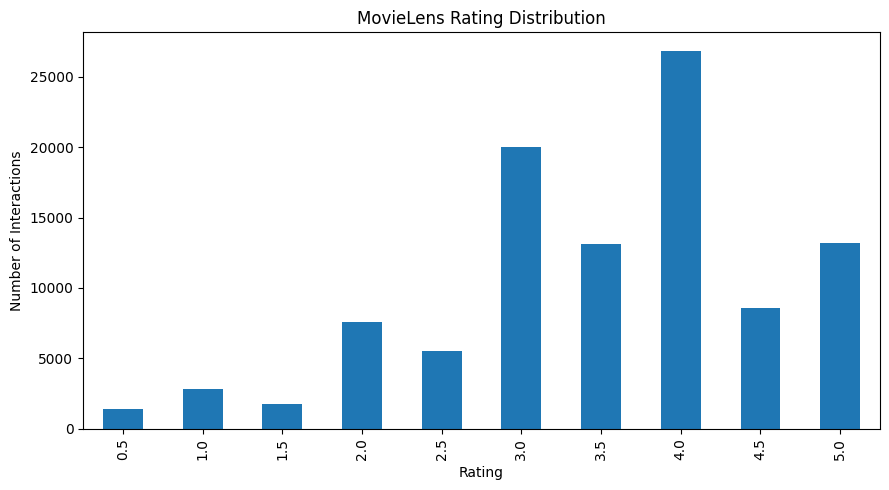

In [9]:
rating_counts = ratings["rating"].value_counts().sort_index()

plt.figure(figsize=(9, 5))
rating_counts.plot(kind="bar")

plt.title("MovieLens Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Interactions")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "rating_distribution.png",
    dpi=150
)
plt.show()

Mức độ hoạt động của User

count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64
Users with fewer than 1 ratings: 0
Users with fewer than 5 ratings: 0
Users with fewer than 10 ratings: 0
Users with fewer than 20 ratings: 0


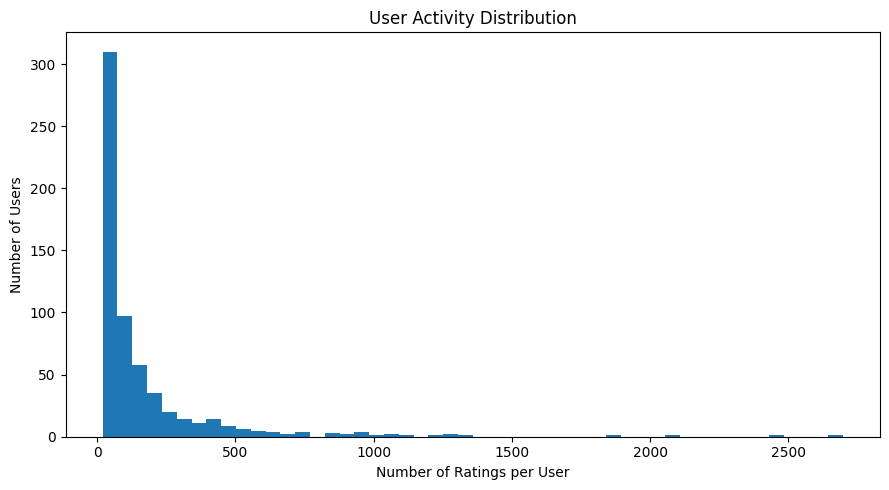

In [10]:
user_activity = ratings.groupby("userId").size()

print(user_activity.describe())

for threshold in [1, 5, 10, 20]:
    count = (user_activity < threshold).sum()
    print(f"Users with fewer than {threshold} ratings: {count}")

plt.figure(figsize=(9, 5))
plt.hist(user_activity, bins=50)

plt.title("User Activity Distribution")
plt.xlabel("Number of Ratings per User")
plt.ylabel("Number of Users")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "user_activity.png",
    dpi=150
)
plt.show()

Mức độ phổ biến của Movie

In [11]:
movie_activity = ratings.groupby("movieId").size()

print(movie_activity.describe())

print("Top 10 most rated movies:")

top_movies = (
    movie_activity
    .sort_values(ascending=False)
    .head(10)
    .rename("rating_count")
    .reset_index()
    .merge(movies, on="movieId", how="left")
)

display(top_movies)

count    9724.000000
mean       10.369807
std        22.401005
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       329.000000
dtype: float64
Top 10 most rated movies:


,movieId,rating_count,title,genres
0,356,329,Forrest Gump (1994),Comedy|Drama|Romance|War
1,318,317,"Shawshank Redemption, The (1994)",Crime|Drama
2,296,307,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller
3,593,279,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller
4,2571,278,"Matrix, The (1999)",Action|Sci-Fi|Thriller
5,260,251,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi
6,480,238,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller
7,110,237,Braveheart (1995),Action|Drama|War
8,589,224,Terminator 2: Judgment Day (1991),Action|Sci-Fi
9,527,220,Schindler's List (1993),Drama|War


Phân tích Genre

,count
genres,
Drama,4361
Comedy,3756
Thriller,1894
Action,1828
Romance,1596
Adventure,1263
Crime,1199
Sci-Fi,980
Horror,978


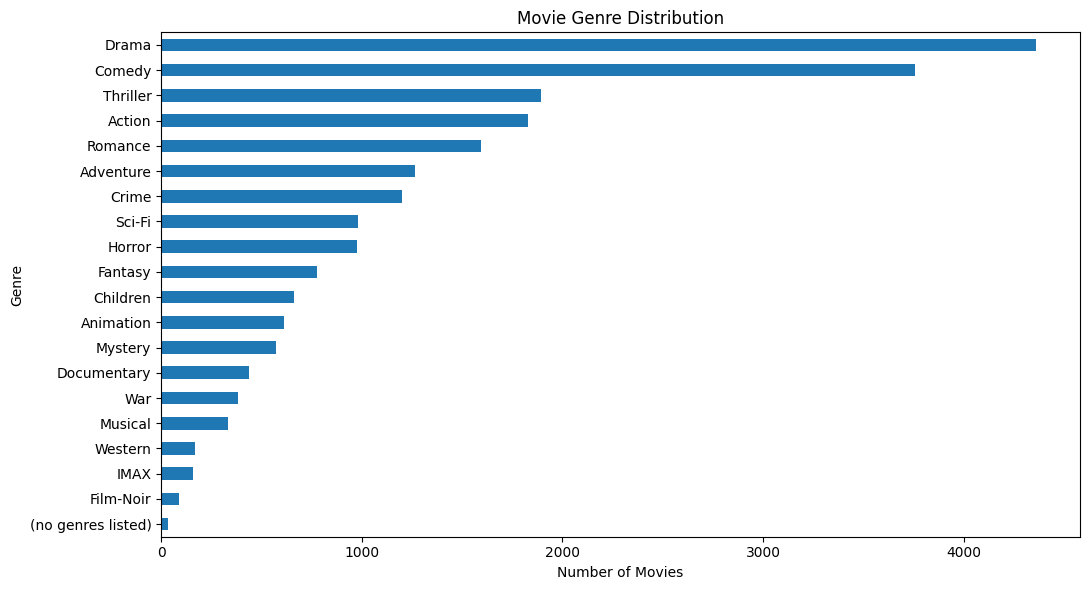

In [12]:
genre_counts = (
    movies["genres"]
    .fillna("(no genres listed)")
    .str.split("|", regex=False)
    .explode()
    .value_counts()
)

display(genre_counts)

plt.figure(figsize=(11, 6))
genre_counts.sort_values().plot(kind="barh")

plt.title("Movie Genre Distribution")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "genre_distribution.png",
    dpi=150
)
plt.show()

Phân tích tương tác theo thời gian

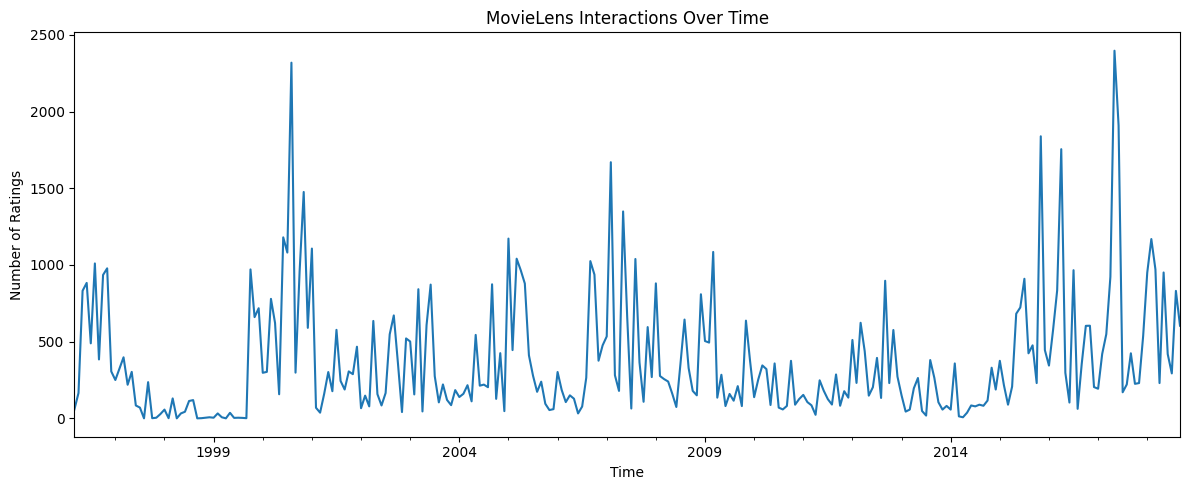

In [13]:
monthly_interactions = (
    ratings
    .set_index("datetime")
    .resample("MS")
    .size()
)

plt.figure(figsize=(12, 5))
monthly_interactions.plot()

plt.title("MovieLens Interactions Over Time")
plt.xlabel("Time")
plt.ylabel("Number of Ratings")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "interactions_over_time.png",
    dpi=150
)
plt.show()

Tạo báo cáo chất lượng dữ liệu

In [14]:
quality_report = {
    **summary,
    "rating_min": float(ratings["rating"].min()),
    "rating_max": float(ratings["rating"].max()),
    "earliest_timestamp": ratings["datetime"].min().isoformat(),
    "latest_timestamp": ratings["datetime"].max().isoformat(),
    "duplicate_user_movie_pairs": int(
        ratings.duplicated(["userId", "movieId"]).sum()
    ),
    "unknown_movie_references": int(
        (~ratings["movieId"].isin(movies["movieId"])).sum()
    ),
    "missing_values": {
        name: {
            column: int(count)
            for column, count in df.isnull().sum().items()
        }
        for name, df in datasets.items()
    },
    "user_activity": {
        key: float(value)
        for key, value in user_activity.describe().items()
    },
    "movie_activity": {
        key: float(value)
        for key, value in movie_activity.describe().items()
    },
    "genre_counts": {
        str(key): int(value)
        for key, value in genre_counts.items()
    },
}

report_path = REPORT_DIR / "data_quality_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(quality_report, f, indent=2, ensure_ascii=False)

print("Saved:", report_path)

Saved: /content/movie-dss/experiments/eda/data_quality_report.json


Kiểm thử Phase 1

In [15]:
assert len(ratings) > 0, "Ratings dataset is empty"
assert len(movies) > 0, "Movies dataset is empty"

assert ratings["userId"].notna().all()
assert ratings["movieId"].notna().all()
assert ratings["rating"].notna().all()
assert ratings["timestamp"].notna().all()

assert ratings["rating"].between(0.5, 5.0).all()

assert set(ratings["movieId"]).issubset(
    set(movies["movieId"])
), "Unknown movie IDs detected"

assert 0 <= density <= 1
assert 0 <= sparsity <= 1

assert report_path.exists()

expected_figures = [
    "rating_distribution.png",
    "user_activity.png",
    "genre_distribution.png",
    "interactions_over_time.png",
]

for filename in expected_figures:
    assert (FIGURE_DIR / filename).exists(), (
        f"Missing figure: {filename}"
    )

print("All Phase 1 tests passed!")

All Phase 1 tests passed!


Đóng gói kết quả

In [16]:
import shutil
from google.colab import files

archive_path = shutil.make_archive(
    "/content/phase1_eda_results",
    "zip",
    root_dir=PROJECT_ROOT,
    base_dir="experiments/eda"
)

files.download(archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>